# Gambit · Répéter, changer, rejouer : ce qui précède une victoire

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hadrienfonrojet/ANALYSE-MARCHE-/blob/main/Gambit.ipynb)

Ce notebook prolonge `Analyse_data.ipynb`. Il reprend la même base de parties Lichess et pose des questions plus fines sur **ce qui entoure une victoire** : la couleur, la répétition de la même famille d’ouverture, l’enchaînement des parties dans le temps et les revanches contre le même adversaire.

### Questions étudiées

1. Combien de parties sont gagnées au total, et avec quelle couleur gagne-t-on le plus ?
2. Gagne-t-on plus souvent la partie suivante quand on **répète la même famille d’ouverture** ?
3. Gagne-t-on plus souvent quand on **garde la même couleur**, selon la couleur et la famille ?
4. Que se passe-t-il quand on garde **à la fois la même famille et la même couleur** ?
5. Ces effets résistent-ils quand on les étudie **ensemble dans une régression**, à niveau égal ?
6. Les résultats suivent-ils une **dynamique temporelle** : évolution par semaine, rang dans une session, enchaînement des victoires ?
7. **Contre le même adversaire**, plusieurs parties d’affilée : vaut-il mieux garder son ouverture ou en changer ?

### Comment lire ce notebook

Chaque analyse suit trois blocs : **ce que l’on fait et pourquoi**, **le code**, puis **l’interprétation** des sorties. Les chiffres commentés portent sur la collecte publiée `donnees/parties_test.parquet` (1 212 observations joueur–partie, 18 comptes). Nous distinguons trois questions. Quel taux observe-t-on dans chaque groupe ? Les données apportent-elles assez d’éléments pour établir une association ? Ce taux aiderait-il à prévoir le résultat d’une nouvelle partie ?

## 0. Préparer les données

### 0.1 Charger et nettoyer la base

**Ce que l’on fait.** On importe les bibliothèques, puis on reconstruit la base nettoyée exactement comme dans `Analyse_data.ipynb` : identification des ouvertures par position, nettoyage, regroupement par **famille** d’ouverture (`Sicilian Defense`, `French Defense`…).

**Pourquoi.** Réutiliser les mêmes fonctions (`creer_openings`, `identifier_parties`, `preparer_parties`) garantit que les deux notebooks analysent les mêmes 1 212 observations de la collecte publiée.

In [1]:
from pathlib import Path
import os, sys, subprocess, warnings

if not Path("config.py").is_file() and Path("../config.py").is_file():
    os.chdir("..")
if not Path("config.py").is_file():  # Colab : récupérer le projet.
    target = Path("/content/jeu_de_la_dame")
    if not target.exists():
        subprocess.run(["git", "clone", "https://github.com/Hadrienfonrojet/ANALYSE-MARCHE-.git", str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:.3f}".format)

import config as cfg
from import_ouvertures import creer_openings
from Master_file import identifier_parties
from nettoyage import preparer_parties

FICHIER = "donnees/parties_test.parquet"
brut = pd.read_parquet(FICHIER)
parties, bilan = preparer_parties(identifier_parties(brut, creer_openings()))
parties = parties.sort_values(["user_id", "date", "game_id"]).reset_index(drop=True)
parties["couleur"] = parties["color"].map({"white": "Blancs", "black": "Noirs"})

print("Parties nettoyées :", len(parties), "| comptes :", parties.user_id.nunique(),
      "| du", parties.date.min().date(), "au", parties.date.max().date())

Parties nettoyées : 1212 | comptes : 18 | du 2026-09-01 au 2026-11-24


**Ce qu’on constate.** Après nettoyage, on a 1 212 observations réparties entre 18 comptes, du 1er septembre au 24 novembre 2026. Une ligne décrit une partie du point de vue d’un compte. Si deux comptes de l’échantillon se rencontrent, ils peuvent tous les deux contribuer une ligne pour cette partie.

Cet échantillon permet d’étudier les comportements des joueurs suivis. Pour généraliser à Lichess, il faudrait vérifier si on retrouve les mêmes résultats sur d’autres comptes et d’autres périodes.

### 0.2 Construire les enchaînements de parties

**Ce que l’on fait.** Pour chaque partie, on ajoute les informations de **la partie suivante du même joueur** : sa famille d’ouverture, sa couleur, son adversaire, son résultat. Le suffixe `_suiv` désigne ces colonnes. On en déduit trois indicateurs :

- `repete` = 1 si la partie suivante est de la **même famille** d’ouverture ;
- `meme_couleur` = 1 si le joueur garde **la même couleur** ;
- `meme_adversaire` = 1 si la partie suivante est **contre le même adversaire** (une revanche).

**Pourquoi.** Toutes les questions de ce notebook comparent une partie à la suivante. On ne garde que les vraies successions : la suivante existe, elle est plus tardive, et aucune partie n’a été retirée entre les deux par le nettoyage (même `_chronology_segment`).

**Une précaution.** La famille d’ouverture est le fruit **des deux joueurs** : avec les Blancs on joue 1.e4, c’est l’adversaire qui choisit la Sicilienne. « Répéter son ouverture » a donc surtout un sens **quand on garde la même couleur** ; c’est pourquoi les deux indicateurs sont étudiés ensemble à la section 4.

In [2]:
g = parties.groupby("user_id", sort=False)
for col in ["game_id", "date", "opening_name", "color", "couleur", "win", "score",
            "opponent_id", "format_partie", "elo_diff", "_chronology_segment"]:
    parties[col + "_suiv"] = g[col].shift(-1)

valide = (parties["game_id_suiv"].notna()
          & parties["date_suiv"].gt(parties["date"])
          & parties["_chronology_segment"].eq(parties["_chronology_segment_suiv"])
          & ~parties["_date_ambiguous"])
trans = parties.loc[valide].copy()

connues = trans["opening_name"].notna() & trans["opening_name_suiv"].notna()
trans["repete"] = (trans["opening_name"] == trans["opening_name_suiv"]).where(connues).astype("float")
trans["meme_couleur"] = (trans["color"] == trans["color_suiv"]).astype(int)
trans["meme_adversaire"] = (trans["opponent_id"] == trans["opponent_id_suiv"]).astype(int)
trans["blancs_suiv"] = (trans["color_suiv"] == "white").astype(int)
trans["elo_suiv_100"] = trans["elo_diff_suiv"].astype(float) / 100
trans["win_suiv"] = trans["win_suiv"].astype(float)
trans["ecart_min"] = (trans["date_suiv"] - trans["date"]).dt.total_seconds() / 60

print("Enchaînements valides :", len(trans), "sur", len(parties) - parties.user_id.nunique(), "possibles")
print("Familles connues des deux côtés :", int(connues.sum()))
print(f"Répète la famille : {trans.repete.mean():.1%} | garde la couleur : {trans.meme_couleur.mean():.1%} "
      f"| même adversaire : {trans.meme_adversaire.sum()} enchaînements")
print("Délai médian entre deux parties :", round(trans.ecart_min.median(), 1), "minutes")

Enchaînements valides : 1182 sur 1194 possibles
Familles connues des deux côtés : 1133
Répète la famille : 14.8% | garde la couleur : 36.4% | même adversaire : 81 enchaînements
Délai médian entre deux parties : 11.7 minutes


**Ce qu’on constate.** Sur 1 194 paires possibles, on garde 1 182 enchaînements. Dans 1 133 d’entre eux, les deux familles sont renseignées. Les 49 autres peuvent servir à étudier la couleur ou le résultat précédent, mais la répétition de l’ouverture reste inconnue.

On retrouve la même famille dans 14,8 % des enchaînements renseignés et la même couleur dans 36,4 % des enchaînements valides. Le groupe « répète » sera donc bien plus petit que le groupe « change ». Quelques victoires de plus ou de moins peuvent faire beaucoup bouger son taux. Le délai médian de 11,7 minutes indique que la moitié des intervalles sont au plus de cette durée. La section sur les sessions examine ensuite ce que donnent les résultats avec un seuil de 30 minutes.

### 0.3 Deux outils réutilisés partout

**Ce que l’on fait.** On écrit deux petites fonctions, pour ne pas répéter le même code à chaque analyse :

- `taux(df, par)` : pour chaque groupe, le nombre de parties, le nombre de victoires, le taux de victoire et son **intervalle de confiance à 95 %** ;
- `chi2(df, x)` : le **test du χ² d’indépendance** entre une variable `x` et la victoire de la partie suivante, avec la p-value et le V de Cramér.

**Pourquoi.** Trois victoires sur quatre donnent 75 %. Le même taux calculé sur 400 parties s’appuie sur beaucoup plus d’observations. On affiche donc les effectifs et un intervalle indicatif, obtenu avec l’approximation normale.

$$\hat p \pm 1{,}96\,\sqrt{\frac{\hat p\,(1-\hat p)}{n}}$$

Ces intervalles donnent un ordre de grandeur. Ils peuvent être peu fiables dans les petits groupes et supposent des observations indépendantes. Or un même joueur apporte plusieurs parties.

Le χ² compare les effectifs observés à ce qu’on attendrait si les deux variables étaient indépendantes. Le V de Cramér renseigne sur la taille de l’association mesurée. Une valeur p élevée indique que les écarts observés restent compatibles avec l’indépendance sous les hypothèses du test. Pour savoir si une variable aide à prévoir de nouvelles parties, il faut mesurer les performances sur des parties gardées à part.

In [3]:
def taux(df, par, cible="win_suiv"):
    t = df.groupby(par, observed=True)[cible].agg(parties="size", victoires="sum", taux="mean")
    marge = 1.96 * np.sqrt(t["taux"] * (1 - t["taux"]) / t["parties"])
    t["ic_bas"], t["ic_haut"] = (t["taux"] - marge).clip(0), (t["taux"] + marge).clip(upper=1)
    t["victoires"] = t["victoires"].astype(int)
    return t


def chi2(df, x, y="win_suiv"):
    tab = pd.crosstab(df[x], df[y])
    stat, p, ddl, attendu = chi2_contingency(tab, correction=False)
    v = np.sqrt(stat / (tab.values.sum() * (min(tab.shape) - 1)))
    return {"test": x, "n": int(tab.values.sum()), "chi2": round(float(stat), 3), "ddl": int(ddl),
            "p": round(float(p), 4), "V_Cramer": round(float(v), 3), "attendu_min": round(float(attendu.min()), 1)}

tests = []  # Tous les tests du notebook, corrigés ensemble par Holm à la fin.
print("Fonctions prêtes.")

Fonctions prêtes.


## 1. Victoires au total et selon la couleur

Nous comptons d’abord les victoires, les nulles et les défaites. Ensuite, nous séparons les Blancs et les Noirs. Puisque la couleur varie d’une partie à l’autre, ce tableau donne un point de repère pour comprendre les analyses de répétition.

Parties : 1212 | victoires : 638 (52.6%) | nulles : 60 (5.0%) | défaites : 514 (42.4%)


,parties,victoires,taux,ic_bas,ic_haut,nulles,score_moyen
couleur,,,,,,,
Blancs,618,337,0.545,0.506,0.585,30,0.570
Noirs,594,301,0.507,0.467,0.547,30,0.532


{'test': 'couleur', 'n': 1212, 'chi2': 1.837, 'ddl': 2, 'p': 0.3991, 'V_Cramer': 0.039, 'attendu_min': 29.4}


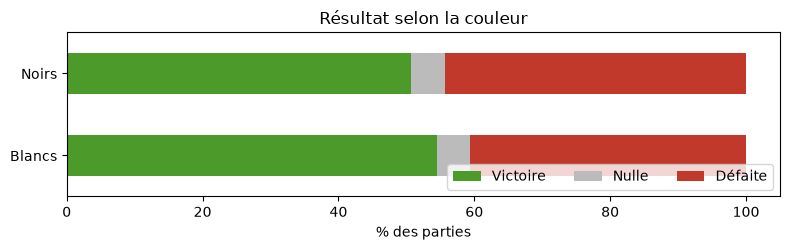

In [4]:
total = parties[["win", "draw", "loss"]].sum()
print(f"Parties : {len(parties)} | victoires : {total.win} ({total.win / len(parties):.1%}) "
      f"| nulles : {total.draw} ({total.draw / len(parties):.1%}) | défaites : {total.loss} ({total.loss / len(parties):.1%})")

par_couleur = taux(parties, "couleur", cible="win")
par_couleur["nulles"] = parties.groupby("couleur")["draw"].sum()
par_couleur["score_moyen"] = parties.groupby("couleur")["score"].mean()
display(par_couleur)

t = chi2(parties, "couleur", y="result")
tests.append({**t, "test": "couleur × résultat (V/N/D)"})
print(t)

ax = (pd.crosstab(parties["couleur"], parties["result"], normalize="index")[["Win", "Draw", "Loss"]] * 100).plot.barh(
    stacked=True, figsize=(8, 2.6), color=["#4c9a2a", "#bbbbbb", "#c0392b"])
ax.set(xlabel="% des parties", ylabel="", title="Résultat selon la couleur")
ax.legend(["Victoire", "Nulle", "Défaite"], loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

**Ce qu’on constate.** Les Blancs gagnent 337 fois sur 618, soit **54,5 %**. Les Noirs gagnent 301 fois sur 594, soit **50,7 %**. L’écart observé est de **3,8 points**. Chaque couleur compte 30 nulles. Le score moyen, qui attribue un demi-point aux nulles, suit le même sens avec 0,570 pour les Blancs et 0,532 pour les Noirs.

**Est-ce suffisant pour prévoir ?** Une probabilité observée de 54,5 % laisse encore 45,5 % de parties sans victoire. Pour une partie précise, connaître la couleur seule donne donc peu d’information. Le χ² donne une valeur p de 0,399 et un V de Cramér de 0,039. Sur notre échantillon, cela ne suffit pas pour conclure à une association entre la couleur et le résultat.

## 2. Répéter la même famille d’ouverture

**Ce que l’on fait.** Sur tous les enchaînements où les deux familles sont connues, on compare le taux de victoire de la partie suivante selon que le joueur **répète** la même famille ou **en change**. On regarde aussi ce taux **après une victoire** et **après une non-victoire**, car « rejouer ce qui vient de marcher » est la question centrale du projet.

**Pourquoi c’est pertinent.** Répéter une ouverture, c’est jouer une position qu’on connaît : on peut s’attendre à un avantage de familiarité. Mais un joueur peut aussi répéter par habitude, quelle que soit sa forme. Séparer l’après-victoire de l’après-défaite permet de distinguer ces deux histoires.

In [5]:
rep = trans.dropna(subset=["repete"]).copy()
rep["choix"] = rep["repete"].map({1.0: "Répète la famille", 0.0: "Change de famille"})
rep["partie_precedente"] = rep["win"].map({1: "après une victoire", 0: "après une nulle ou défaite"})

print("Taux de victoire de la partie suivante")
display(taux(rep, "choix"))
print("Selon le résultat de la partie précédente")
display(taux(rep, ["partie_precedente", "choix"]))

for nom, sous in [("répétition (tous)", rep), ("répétition après victoire", rep[rep.win == 1]),
                  ("répétition après non-victoire", rep[rep.win == 0])]:
    t = chi2(sous, "repete"); tests.append({**t, "test": nom}); print(t)

Taux de victoire de la partie suivante


,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
Change de famille,965,503,0.521,0.490,0.553
Répète la famille,168,94,0.560,0.484,0.635


Selon le résultat de la partie précédente


parties  victoires  taux  \
partie_precedente          choix                                         
après une nulle ou défaite Change de famille      454        205 0.452   
                           Répète la famille       81         39 0.481   
après une victoire         Change de famille      511        298 0.583   
                           Répète la famille       87         55 0.632   

                                              ic_bas  ic_haut  
partie_precedente          choix                               
après une nulle ou défaite Change de famille   0.406    0.497  
                           Répète la famille   0.373    0.590  
après une victoire         Change de famille   0.540    0.626  
                           Répète la famille   0.531    0.734

{'test': 'repete', 'n': 1133, 'chi2': 0.841, 'ddl': 1, 'p': 0.3591, 'V_Cramer': 0.027, 'attendu_min': 79.5}
{'test': 'repete', 'n': 598, 'chi2': 0.738, 'ddl': 1, 'p': 0.3902, 'V_Cramer': 0.035, 'attendu_min': 35.6}


{'test': 'repete', 'n': 535, 'chi2': 0.248, 'ddl': 1, 'p': 0.6182, 'V_Cramer': 0.022, 'attendu_min': 36.9}


**Ce qu’on constate.** On gagne la partie suivante dans **56,0 %** des cas quand on retrouve la même famille d’ouverture (94 sur 168), contre **52,1 %** quand on en change (503 sur 965). Après une victoire, les taux passent à **63,2 % contre 58,3 %**. Après une nulle ou une défaite, ils tombent à **48,1 % contre 45,2 %**.

La différence après victoire est de **4,9 points**. Elle correspond à 55 victoires sur 87 répétitions. À titre d’exemple, quatre victoires de moins dans ce groupe ramèneraient son taux de 63,2 % à 58,6 %, très près des 58,3 % du groupe qui change. L’écart repose donc sur un nombre limité de parties.

**Ce qu’on peut conclure.** Les écarts vont dans le même sens dans les trois comparaisons, mais les valeurs p vont de 0,36 à 0,62. Ces résultats ne suffisent pas à établir un lien entre répétition et victoire suivante. Les 63,2 % décrivent une fréquence observée. Ils ne suffisent pas à prévoir qui gagnera une nouvelle partie, dont le résultat dépend aussi des joueurs et de l’adversaire.

## 3. Garder la même couleur

**Ce que l’on fait.** On compare le taux de victoire de la partie suivante selon que le joueur **garde** ou **change** de couleur, en distinguant la couleur de la partie suivante (Blancs → Blancs, Noirs → Noirs, Blancs → Noirs, Noirs → Blancs). On croise ensuite avec les **familles d’ouverture** les plus jouées.

**Pourquoi c’est pertinent.** Dans notre échantillon, la couleur change souvent lorsque deux parties se suivent contre le même adversaire. Garder la couleur peut donc signaler un autre contexte de jeu. Et comme les Blancs ont l’avantage du premier coup (section 1), il faut séparer « garder la couleur » de « jouer les Blancs » : c’est le rôle du tableau couleur précédente × couleur suivante.

In [6]:
trans["passage"] = trans["couleur"] + " → " + trans["couleur_suiv"]
print("Taux de victoire selon la couleur précédente et la couleur suivante")
display(taux(trans, ["meme_couleur", "passage"]))

t = chi2(trans, "meme_couleur"); tests.append({**t, "test": "même couleur"}); print(t)
for c in ["Blancs", "Noirs"]:
    t = chi2(trans[trans.couleur_suiv == c], "meme_couleur")
    tests.append({**t, "test": f"même couleur, partie suivante avec les {c}"}); print(c, t)

# Par famille d'ouverture de la partie suivante, pour les familles assez jouées.
frequentes = trans["opening_name_suiv"].value_counts()
frequentes = frequentes[frequentes >= 40].index
tab = (trans[trans.opening_name_suiv.isin(frequentes)]
       .pivot_table(index="opening_name_suiv", columns="meme_couleur", values="win_suiv", aggfunc=["mean", "size"]))
tab.columns = ["taux_change_couleur", "taux_garde_couleur", "n_change", "n_garde"]
tab["ecart_points"] = 100 * (tab["taux_garde_couleur"] - tab["taux_change_couleur"])
display(tab.sort_values("n_change", ascending=False))

Taux de victoire selon la couleur précédente et la couleur suivante


parties  victoires  taux  ic_bas  ic_haut
meme_couleur passage                                                   
0            Blancs → Noirs       375        204 0.544   0.494    0.594
             Noirs → Blancs       377        201 0.533   0.483    0.584
1            Blancs → Blancs      225        125 0.556   0.491    0.620
             Noirs → Noirs        205         89 0.434   0.366    0.502

{'test': 'meme_couleur', 'n': 1182, 'chi2': 1.834, 'ddl': 1, 'p': 0.1757, 'V_Cramer': 0.039, 'attendu_min': 204.8}
Blancs {'test': 'meme_couleur', 'n': 602, 'chi2': 0.285, 'ddl': 1, 'p': 0.5936, 'V_Cramer': 0.022, 'attendu_min': 103.2}
Noirs {'test': 'meme_couleur', 'n': 580, 'chi2': 6.399, 'ddl': 1, 'p': 0.0114, 'V_Cramer': 0.105, 'attendu_min': 101.4}


,taux_change_couleur,taux_garde_couleur,n_change,n_garde,ecart_points
opening_name_suiv,,,,,
Sicilian Defense,0.533,0.667,122,72,13.388
French Defense,0.667,0.559,63,34,-10.784
Queen's Pawn Game,0.426,0.417,61,24,-0.956
Caro-Kann Defense,0.692,0.550,52,40,-14.231
Van't Kruijs Opening,0.405,0.471,37,17,6.518
Hungarian Opening,0.676,0.524,34,21,-15.266
Ruy Lopez,0.688,0.167,32,12,-52.083
English Opening,0.467,0.467,30,15,0.000


**Ce qu’on constate.** Lorsqu’on garde la couleur, on observe **49,8 %** de victoires, contre **53,9 %** quand on en change. Le χ² global donne p ≈ 0,18. Le passage Noirs → Noirs ressort avec 89 victoires sur 205, soit **43,4 %**. Son test brut donne p ≈ 0,011, puis p ≈ 0,125 après correction de Holm.

Les résultats par famille montrent pourquoi les effectifs comptent. Avec la Sicilienne, les taux sont de 66,7 % à couleur gardée et de 53,3 % à couleur changée. Avec la Ruy Lopez, le groupe qui garde la couleur ne compte que 12 observations et deux victoires. Une seule victoire supplémentaire y changerait le taux de 8,3 points. Ces écarts sont des pistes à examiner. Ils sont trop incertains pour utiliser la couleur comme règle de prévision par famille.

## 4. Même famille et même couleur

**Ce que l’on fait.** On croise les deux décisions : répéter ou non la famille, garder ou non la couleur. On obtient quatre situations, et pour chacune le taux de victoire de la partie suivante. Le test du χ² porte sur ce tableau 4 × 2.

**Pourquoi c’est pertinent.** C’est la définition la plus juste de « rejouer son ouverture » : la même famille **avec la même couleur**, donc vraisemblablement le même répertoire choisi par le joueur. Si un avantage de familiarité existe, c’est dans la case « même famille, même couleur » qu’il doit apparaître.

,parties,victoires,taux,ic_bas,ic_haut
situation,,,,,
même famille / même couleur,105,61,0.581,0.487,0.675
autre famille / autre couleur,663,357,0.538,0.501,0.576
même famille / autre couleur,63,33,0.524,0.400,0.647
autre famille / même couleur,302,146,0.483,0.427,0.540


{'test': 'situation', 'n': 1133, 'chi2': 3.876, 'ddl': 3, 'p': 0.2751, 'V_Cramer': 0.058, 'attendu_min': 29.8}
À couleur gardée : {'test': 'repete', 'n': 407, 'chi2': 2.964, 'ddl': 1, 'p': 0.0851, 'V_Cramer': 0.085, 'attendu_min': 51.6}


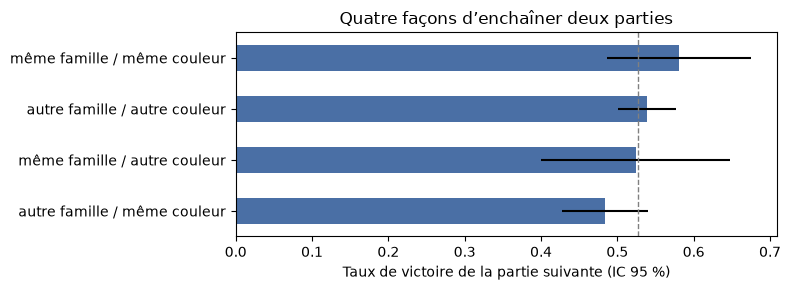

In [7]:
rep["situation"] = (rep["repete"].map({1.0: "même famille", 0.0: "autre famille"}) + " / "
                    + rep["meme_couleur"].map({1: "même couleur", 0: "autre couleur"}))
quatre = taux(rep, "situation").sort_values("taux", ascending=False)
display(quatre)

t = chi2(rep, "situation"); tests.append({**t, "test": "famille × couleur (4 situations)"}); print(t)
meme = rep[rep.meme_couleur == 1]
t = chi2(meme, "repete"); tests.append({**t, "test": "répétition, à couleur gardée"}); print("À couleur gardée :", t)

ax = quatre.sort_values("taux").plot.barh(y="taux", xerr=[quatre.sort_values("taux").eval("taux - ic_bas"),
                                                          quatre.sort_values("taux").eval("ic_haut - taux")],
                                          legend=False, figsize=(8, 3), color="#4a6fa5")
ax.axvline(rep["win_suiv"].mean(), color="grey", ls="--", lw=1)
ax.set(xlabel="Taux de victoire de la partie suivante (IC 95 %)", ylabel="",
       title="Quatre façons d’enchaîner deux parties")
plt.tight_layout(); plt.show()

**Ce qu’on constate.** Quand la couleur reste la même, on gagne **58,1 %** des parties suivantes en retrouvant la même famille (61 sur 105), contre **48,3 %** quand la famille change (146 sur 302). L’écart observé est de **9,8 points**. C’est le contraste brut qui correspond le mieux à notre question sur la familiarité avec une ouverture. La famille jouée dépend toutefois des coups des deux joueurs.

**Est-ce suffisant ?** Pour les quatre situations réunies, le χ² donne p ≈ 0,275. Pour la seule comparaison à couleur gardée, il donne p ≈ 0,085 avant correction de Holm et p ≈ 0,851 après correction. Le graphique montre une piste, mais le test brut ne suffit pas à établir une association. Avec 44 parties sans victoire sur 105 dans la case en tête, cette combinaison ne permet pas de prévoir à elle seule le résultat.

## 5. Tout réunir dans une régression

**Ce que l’on fait.** On estime la probabilité de gagner la partie suivante en fonction de **toutes les variables à la fois** :

$$\Pr(\text{victoire}_{t+1}) = \alpha_{\text{joueur}} + \beta_1\,\text{répète} + \beta_2\,\text{même couleur} + \beta_3\,(\text{répète}\times\text{même couleur}) + \beta_4\,\text{victoire}_t + \beta_5\,\text{Blancs}_{t+1} + \beta_6\,\frac{\Delta \text{Elo}_{t+1}}{100} + \gamma_{\text{cadence}} + \varepsilon$$

Trois modèles, du plus simple au plus complet :

| Modèle | Variables | Ce qu’il teste |
|---|---|---|
| M1 | répète, même couleur, interaction | Les effets bruts des deux décisions |
| M2 | M1 + victoire précédente, Blancs, écart Elo, cadence | Les mêmes effets **à niveau, couleur et cadence égaux** |
| M3 | M2 + un effet fixe par joueur (`C(user_id)`) | Les mêmes effets **à l’intérieur d’un même joueur** |

**Pourquoi c’est pertinent.** Les comparaisons des sections 2 à 4 mélangent des joueurs différents : un joueur fort gagne souvent **et** peut répéter souvent, sans que la répétition y soit pour quelque chose. L’**effet fixe joueur** (M3) compare chaque joueur à lui-même ; c’est la version la plus exigeante. Les coefficients d’un modèle de probabilité linéaire se lisent directement en **points de probabilité**. Les erreurs-types sont **groupées par joueur**, car les parties d’un même joueur ne sont pas indépendantes ; avec 17 joueurs, ces erreurs-types restent approximatives. Une **régression logistique** vérifie enfin que les conclusions ne tiennent pas au choix du modèle linéaire.

In [8]:
donnees = rep.dropna(subset=["elo_suiv_100", "format_partie_suiv"]).copy()
donnees["format_suiv"] = donnees["format_partie_suiv"].astype(str)
formules = {
    "M1 brut": "win_suiv ~ repete * meme_couleur",
    "M2 contrôles": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv)",
    "M3 effet fixe joueur": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv) + C(user_id)",
}
lignes, modeles = [], {}
for nom, f in formules.items():
    m = smf.ols(f, data=donnees).fit(cov_type="cluster", cov_kwds={"groups": donnees["user_id"]})
    modeles[nom] = m
    for v in ["repete", "meme_couleur", "repete:meme_couleur", "win", "blancs_suiv", "elo_suiv_100"]:
        if v in m.params:
            bas, haut = m.conf_int().loc[v]
            lignes.append({"modèle": nom, "variable": v, "effet (points)": 100 * m.params[v],
                           "IC bas": 100 * bas, "IC haut": 100 * haut, "p": m.pvalues[v]})
coef = pd.DataFrame(lignes)
display(coef.pivot(index="variable", columns="modèle", values="effet (points)").round(2))
print("Détail du modèle M3 (effets en points de probabilité, IC 95 %) — n =", int(modeles["M3 effet fixe joueur"].nobs))
display(coef[coef["modèle"] == "M3 effet fixe joueur"].drop(columns="modèle").round(3))
print("R² :", {k: round(float(m.rsquared), 3) for k, m in modeles.items()})

# Effet total de répéter quand on garde la couleur (β1 + β3) dans M3.
m3 = modeles["M3 effet fixe joueur"]
total = m3.t_test("repete + repete:meme_couleur = 0")
print(f"Répéter à couleur gardée (β1 + β3) : {100 * total.effect.item():+.1f} points, p = {total.pvalue.item():.3f}")

modèle,M1 brut,M2 contrôles,M3 effet fixe joueur
variable,,,
blancs_suiv,NaN,0.860,1.420
elo_suiv_100,NaN,7.600,6.370
meme_couleur,-5.500,-4.540,-4.100
repete,-1.470,-6.090,-8.130
repete:meme_couleur,11.220,14.270,14.480
win,NaN,1.220,-2.410


Détail du modèle M3 (effets en points de probabilité, IC 95 %) — n = 1133


,variable,effet (points),IC bas,IC haut,p
9,repete,-8.134,-19.085,2.817,0.145
10,meme_couleur,-4.100,-9.811,1.611,0.159
11,repete:meme_couleur,14.476,2.998,25.954,0.013
12,win,-2.409,-8.849,4.031,0.463
13,blancs_suiv,1.419,-4.697,7.535,0.649
14,elo_suiv_100,6.374,4.545,8.204,0.000


R² : {'M1 brut': 0.003, 'M2 contrôles': 0.189, 'M3 effet fixe joueur': 0.211}
Répéter à couleur gardée (β1 + β3) : +6.3 points, p = 0.020


In [9]:
# Vérification : régression logistique (M2), effets marginaux moyens en points de probabilité.
logit = smf.logit(formules["M2 contrôles"], data=donnees).fit(disp=False, cov_type="cluster",
                                                                cov_kwds={"groups": donnees["user_id"]})
effets = logit.get_margeff(at="overall").summary_frame()
effets = (100 * effets[["dy/dx", "Conf. Int. Low", "Cont. Int. Hi."]]).join(effets[["Pr(>|z|)"]])
effets.columns = ["effet (points)", "IC bas", "IC haut", "p"]
display(effets.loc[[i for i in effets.index if not i.startswith("C(")]].round(3))

,effet (points),IC bas,IC haut,p
repete,-7.146,-17.607,3.315,0.181
meme_couleur,-3.710,-9.865,2.444,0.237
repete:meme_couleur,14.514,4.050,24.977,0.007
win,-0.460,-7.416,6.496,0.897
blancs_suiv,0.521,-5.695,6.737,0.870
elo_suiv_100,9.802,7.660,11.945,0.000


**Ce qu’on constate.** Dans M3, quand la couleur change, retrouver la même famille est associé à **−8,1 points** de probabilité de victoire. Si la couleur est gardée, l’interaction ajoute **+14,5 points**. La question « répéter ou changer à couleur gardée ? » se lit donc en additionnant les deux termes. On trouve **+6,3 points**, avec une valeur p d’environ **0,020** pour la somme.

C’est un signal intéressant après prise en compte de l’Elo, de la cadence, de la couleur suivante et des différences stables entre joueurs. Il mérite d’être vérifié. On compte seulement **17 joueurs** dans les régressions et **105 enchaînements** dans le groupe « même famille, même couleur ». Le contraste du modèle se situe en dehors de la correction de Holm de la section 8. La colonne de l’interaction dans le modèle logistique va dans le même sens, mais sa valeur ne mesure pas directement le contraste de +6,3 points.

L’Elo apporte aussi de l’information. Dans M3, **100 points d’avance supplémentaires** sont associés à **+6,4 points** de probabilité de victoire, les autres variables étant fixées. Le $R^2$ passe de 0,003 dans le modèle brut à 0,189 quand on ajoute l’ensemble des contrôles, puis à 0,211 avec les effets fixes. Il décrit l’ajustement dans l’échantillon. Pour savoir si répéter améliore vraiment les prévisions, il faudrait comparer un modèle avec et sans répétition sur des parties ultérieures laissées de côté.

## 6. La dynamique dans le temps

### 6.1 Évolution semaine par semaine

**Ce que l’on fait.** On calcule le nombre de parties et le taux de victoire pour chaque semaine de la période.

**Pourquoi c’est pertinent.** Une série temporelle montre si les résultats sont stables ou s’ils dérivent (progression, période de méforme). Elle montre aussi **comment la collecte est construite** : l’API renvoie les parties les plus récentes de chaque compte, donc les dernières semaines pèsent beaucoup plus que les premières. Il faut le savoir avant de comparer deux périodes.

,parties,taux,comptes
2026-08-31,6,1.000,3
2026-09-07,27,0.370,3
2026-09-14,40,0.525,7
2026-09-21,24,0.417,3
2026-09-28,36,0.250,5
2026-10-05,23,0.652,7
2026-10-12,66,0.591,5
2026-10-19,60,0.783,8
2026-10-26,72,0.542,10
2026-11-02,149,0.577,10


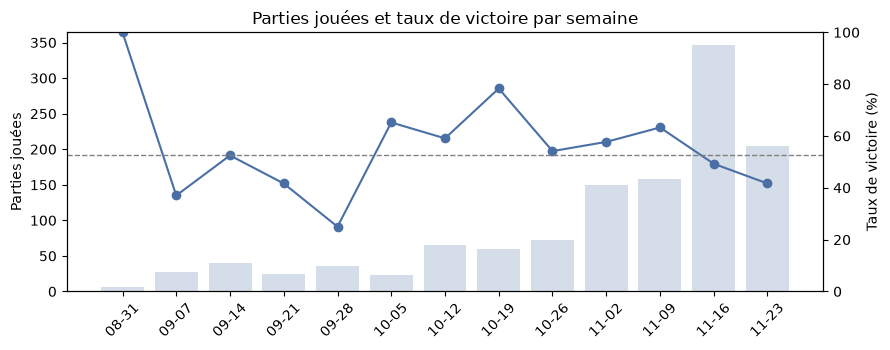

In [10]:
semaine = parties.set_index("date").resample("W-MON", label="left", closed="left")
hebdo = pd.DataFrame({"parties": semaine["win"].size(), "taux": semaine["win"].mean(),
                      "comptes": semaine["user_id"].nunique()})
hebdo.index = hebdo.index.date
display(hebdo)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(hebdo)), hebdo["parties"], color="#d5dde8", label="parties jouées")
ax.set_ylabel("Parties jouées")
ax2 = ax.twinx()
ax2.plot(range(len(hebdo)), 100 * hebdo["taux"], "o-", color="#4a6fa5", label="taux de victoire")
ax2.axhline(100 * parties["win"].mean(), color="grey", ls="--", lw=1)
ax2.set_ylabel("Taux de victoire (%)"); ax2.set_ylim(0, 100)
ax.set_xticks(range(len(hebdo)), [str(d)[5:] for d in hebdo.index], rotation=45)
ax.set_title("Parties jouées et taux de victoire par semaine")
plt.tight_layout(); plt.show()

**Ce qu’on constate.** Le point à **100 %** représente six victoires en six observations, issues de trois comptes. Le point à **25 %** représente 36 observations. On a donc de bonnes raisons de lire les effectifs avant de commenter les pics et les creux de la courbe.

Les trois dernières semaines regroupent **709 observations sur 1 212**, soit environ 58 %. Parmi les semaines de plus de 100 observations, les taux vont d’environ 42 % à 63 %. Les comptes présents changent d’une semaine à l’autre et la dernière semaine est incomplète. La courbe décrit cette collecte. Elle ne suffit pas à montrer que les mêmes joueurs progressent ou régressent au fil du temps.

### 6.2 Le rang dans une session

**Ce que l’on fait.** On découpe l’historique de chaque joueur en **sessions** : deux parties séparées de plus de 30 minutes appartiennent à deux sessions différentes. On calcule ensuite le taux de victoire selon le rang de la partie dans la session (1re, 2e, 3e…).

**Pourquoi c’est pertinent.** On joue souvent plusieurs parties d’affilée. La fatigue, l’échauffement ou l’énervement après une défaite (le « tilt ») peuvent faire varier les résultats au fil de la session. C’est aussi le cadre naturel de la répétition d’ouverture : on répète dans une session, rarement d’un jour à l’autre.

In [11]:
ecart = parties.groupby("user_id")["date"].diff().dt.total_seconds().div(60)
parties["nouvelle_session"] = ecart.isna() | (ecart > 30)
parties["session"] = parties.groupby("user_id")["nouvelle_session"].cumsum()
parties["rang"] = parties.groupby(["user_id", "session"]).cumcount() + 1
parties["rang_session"] = pd.cut(parties["rang"], [0, 1, 2, 3, 5, 10, 1000],
                                 labels=["1re", "2e", "3e", "4e-5e", "6e-10e", "11e et +"])
tailles = parties.groupby(["user_id", "session"]).size()
print(f"Sessions : {len(tailles)} | parties par session : médiane {tailles.median():.0f}, "
      f"moyenne {tailles.mean():.1f}, maximum {tailles.max()}")
display(taux(parties, "rang_session", cible="win"))
t = chi2(parties, "rang_session", y="win"); tests.append({**t, "test": "rang dans la session"}); print(t)

Sessions : 467 | parties par session : médiane 1, moyenne 2.6, maximum 30


,parties,victoires,taux,ic_bas,ic_haut
rang_session,,,,,
1re,467,240,0.514,0.469,0.559
2e,216,118,0.546,0.480,0.613
3e,128,74,0.578,0.493,0.664
4e-5e,152,80,0.526,0.447,0.606
6e-10e,157,81,0.516,0.438,0.594
11e et +,92,45,0.489,0.387,0.591


{'test': 'rang_session', 'n': 1212, 'chi2': 2.59, 'ddl': 5, 'p': 0.7629, 'V_Cramer': 0.046, 'attendu_min': 43.6}


**Ce qu’on constate.** La médiane est d’une partie par session selon notre seuil de 30 minutes. Le taux de victoire atteint **57,8 %** à la troisième partie, contre **51,4 %** à la première. À partir de la onzième, il est de **48,9 %**.

Toutes les sessions entrent dans le premier taux, mais seules les plus longues peuvent entrer dans le dernier. Les groupes peuvent donc différer par les joueurs, la cadence ou les circonstances. Avec p ≈ 0,76 au χ², cette comparaison ne suffit pas à conclure que le rang dans la session est associé à la victoire. Le creux de fin de session reste compatible avec plusieurs explications, dont la fatigue ou la composition du groupe.

### 6.3 Une victoire en appelle-t-elle une autre ?

**Ce que l’on fait.** On compare le taux de victoire de la partie suivante **après une victoire** et **après une nulle ou une défaite**, d’abord brut, puis **à l’intérieur de chaque joueur** (effet fixe joueur), à écart Elo égal.

**Pourquoi c’est pertinent.** C’est la question de la « main chaude » : les succès s’enchaînent-ils ? Le piège est connu : un joueur fort gagne souvent, donc ses victoires se suivent **même sans aucune dynamique**. Seule la comparaison d’un joueur avec lui-même répond vraiment à la question.

In [12]:
display(taux(trans.assign(precedente=trans["win"].map({1: "après victoire", 0: "après nulle ou défaite"})),
             "precedente"))
t = chi2(trans, "win"); tests.append({**t, "test": "victoire précédente (brut)"}); print(t)

fe = trans.dropna(subset=["elo_suiv_100"])
for nom, f in [("brut", "win_suiv ~ win"),
               ("écart Elo", "win_suiv ~ win + elo_suiv_100"),
               ("écart Elo + effet fixe joueur", "win_suiv ~ win + elo_suiv_100 + C(user_id)")]:
    m = smf.ols(f, data=fe).fit(cov_type="cluster", cov_kwds={"groups": fe["user_id"]})
    bas, haut = 100 * m.conf_int().loc["win"]
    print(f"{nom:32s} effet d’une victoire précédente : {100 * m.params['win']:+.1f} points "
          f"[{bas:+.1f} ; {haut:+.1f}], p = {m.pvalues['win']:.3f}")

,parties,victoires,taux,ic_bas,ic_haut
precedente,,,,,
après nulle ou défaite,562,256,0.456,0.414,0.497
après victoire,620,363,0.585,0.547,0.624


{'test': 'win', 'n': 1182, 'chi2': 19.963, 'ddl': 1, 'p': 0.0, 'V_Cramer': 0.13, 'attendu_min': 267.7}
brut                             effet d’une victoire précédente : +13.0 points [+2.5 ; +23.5], p = 0.015
écart Elo                        effet d’une victoire précédente : +1.7 points [-5.3 ; +8.6], p = 0.643
écart Elo + effet fixe joueur    effet d’une victoire précédente : -2.0 points [-7.9 ; +3.9], p = 0.507


**Ce qu’on constate.** Après une victoire, on gagne **58,5 %** des parties suivantes, contre **45,6 %** après une nulle ou une défaite. C’est un écart brut d’environ **13 points**. Il tombe à **+1,7 point** quand on ajoute l’Elo, puis à **−2,0 points** quand on compare chaque joueur à lui-même à écart Elo comparable. L’intervalle de cette dernière estimation va de −7,9 à +3,9 points.

**Est-ce utile pour prévoir ?** Sur les mêmes 1 182 transitions, dire « victoire » à chaque fois aurait donné **619 bonnes réponses, soit 52,4 %**. Dire « victoire » seulement après une victoire et « pas de victoire » après les autres résultats aurait donné **669 bonnes réponses, soit 56,6 %**. C’est une comparaison sur les données déjà observées. Elle ne garantit aucun gain sur des parties futures, ni un gain supplémentaire par rapport à un modèle qui connaît l’Elo. Après ajustement, les résultats ne suffisent pas à établir une dynamique de « main chaude ».

## 7. Plusieurs parties d’affilée contre le même adversaire

**Ce que l’on fait.** On isole les enchaînements où la partie suivante est jouée **contre le même adversaire** (une revanche). On y compare le taux de victoire selon que le joueur **garde** ou **change** de famille d’ouverture, puis selon le résultat de la première partie.

**Pourquoi c’est pertinent.** Contre le même adversaire, l’ouverture devient un choix stratégique : rejouer la même ligne, c’est parier que l’adversaire ne s’est pas adapté ; en changer, c’est le surprendre. On suit la même paire de joueurs d’une partie à l’autre. D’une paire à l’autre, les écarts de niveau peuvent toutefois être très différents.

**Est-ce possible avec nos données ?** Oui : chaque partie contient l’identifiant de l’adversaire (`opponent_id`). Mais les revanches sont rares dans cet échantillon ; les effectifs sont affichés pour juger de ce que l’on peut conclure. Avec de petits effectifs, on utilise le **test exact de Fisher** plutôt que le χ².

In [13]:
rev = trans[trans["meme_adversaire"] == 1].copy()
print(f"Revanches : {len(rev)} enchaînements, {rev.user_id.nunique()} comptes | "
      f"délai médian {rev.ecart_min.median():.1f} min")
print("Cadences :", rev["format_partie_suiv"].value_counts().to_dict())
print(f"Couleur inversée dans {1 - rev.meme_couleur.mean():.0%} des revanches")

rev_conn = rev.dropna(subset=["repete"]).assign(choix=lambda d: d["repete"].map({1.0: "garde la famille", 0.0: "change de famille"}))
print("Taux de victoire de la revanche selon le choix d’ouverture")
display(taux(rev_conn, "choix"))
odds, p = fisher_exact(pd.crosstab(rev_conn["repete"], rev_conn["win_suiv"]))
tests.append({"test": "revanche : garder la famille (Fisher)", "n": len(rev_conn), "p": round(float(p), 4)})
print(f"Fisher : odds ratio = {odds:.2f}, p = {p:.3f}")

print("Taux de victoire de la revanche selon la première partie")
display(taux(rev.assign(premiere=rev["win"].map({1: "première partie gagnée", 0: "première partie non gagnée"})), "premiere"))
odds, p = fisher_exact(pd.crosstab(rev["win"], rev["win_suiv"]))
tests.append({"test": "revanche : résultat de la première partie (Fisher)", "n": len(rev), "p": float(p)})
print(f"Fisher : odds ratio = {odds:.2f}, p = {p:.2g}")

Revanches : 81 enchaînements, 12 comptes | délai médian 1.4 min
Cadences : {'bullet': 54, 'rapid': 19, 'blitz': 7, 'classical': 1}
Couleur inversée dans 93% des revanches
Taux de victoire de la revanche selon le choix d’ouverture


,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
change de famille,61,42,0.689,0.572,0.805
garde la famille,18,12,0.667,0.449,0.884


Fisher : odds ratio = 0.90, p = 1.000
Taux de victoire de la revanche selon la première partie


,parties,victoires,taux,ic_bas,ic_haut
premiere,,,,,
première partie gagnée,57,48,0.842,0.747,0.937
première partie non gagnée,24,8,0.333,0.145,0.522


Fisher : odds ratio = 10.67, p = 1.4e-05


**Ce qu’on constate.** On appelle ici « revanche » deux parties observées d’affilée contre le même adversaire. On en trouve **81**, issues de 12 comptes. Le délai médian est de 1,4 minute et la couleur s’inverse dans 93 % des cas.

Quand les familles sont connues, la victoire suivante atteint **66,7 %** en gardant la famille (12 sur 18) et **68,9 %** en changeant (42 sur 61). Fisher donne p = 1,00. Avec seulement 18 répétitions, les données laissent trop d’incertitude pour conclure sur l’intérêt de garder l’ouverture.

Le premier résultat renseigne davantage dans cet échantillon. Après une première partie gagnée, le joueur gagne **48 revanches sur 57 (84,2 %)**. Après une première partie non gagnée, il en gagne **8 sur 24 (33,3 %)**. C’est un écart important, mais plusieurs revanches peuvent concerner les mêmes joueurs. Le premier résultat peut refléter une différence de niveau entre les deux adversaires. Ces chiffres ne suffisent pas à distinguer cette explication d’un effet lié à la première victoire ni à garantir 84 % de réussite lors de futures revanches.

## 8. Bilan des tests et correction pour tests multiples

**Ce que l’on fait.** On rassemble tous les tests du notebook et on corrige leurs p-values par la méthode de **Holm**.

**Pourquoi c’est pertinent.** Plus on multiplie les comparaisons, plus on risque de prendre un écart dû au hasard pour un signal. Holm ajuste les valeurs p pour tenir compte du nombre de comparaisons.

In [14]:
bilan_tests = pd.DataFrame(tests)
bilan_tests["p_Holm"] = multipletests(bilan_tests["p"], method="holm")[1]
bilan_tests["significatif (5 %, Holm)"] = bilan_tests["p_Holm"] < 0.05
display(bilan_tests[["test", "n", "p", "p_Holm", "significatif (5 %, Holm)"]].sort_values("p").reset_index(drop=True))

,test,n,p,p_Holm,"significatif (5 %, Holm)"
0,victoire précédente (brut),1182,0.000,0.000,True
1,revanche : résultat de la première partie (Fis...,81,0.000,0.000,True
2,"même couleur, partie suivante avec les Noirs",580,0.011,0.125,False
3,"répétition, à couleur gardée",407,0.085,0.851,False
4,même couleur,1182,0.176,1.000,False
5,famille × couleur (4 situations),1133,0.275,1.000,False
6,répétition (tous),1133,0.359,1.000,False
7,répétition après victoire,598,0.390,1.000,False
8,couleur × résultat (V/N/D),1212,0.399,1.000,False
9,"même couleur, partie suivante avec les Blancs",602,0.594,1.000,False


**Ce qu’on constate.** Deux comparaisons sur treize restent sous 5 % après correction de Holm. Elles concernent le résultat précédent, d’abord sur l’ensemble des transitions, puis dans le sous-groupe des revanches. Le 0,000 affiché correspond à un arrondi. Les comparaisons sur la répétition, la couleur et le rang de session dépassent le seuil après correction.

Holm tient compte du nombre de tests. Les observations d’un même compte restent liées, et les deux comparaisons retenues peuvent partager des parties. Les résultats décrivent donc des associations brutes à examiner. Le contraste ajusté de la section 5 appartient à une autre analyse.

## 9. Conclusion

On constate que la probabilité observée de gagner la partie suivante est de **63,2 % quand on retrouve la même famille après une victoire**, contre **58,3 % quand on en change**. L’écart de **4,9 points** va dans le sens de notre hypothèse, mais le χ² donne p ≈ 0,39. Ce résultat ne nous paraît pas suffisant pour conclure à une association entre la répétition seule et la victoire suivante.

La piste la plus intéressante est de regarder la famille **et** la couleur ensemble. À couleur gardée, l’écart brut est de **9,8 points** et le modèle avec effets fixes l’estime à **+6,3 points** après ajustement. Les résultats bruts et le modèle donnent deux lectures de la même question. Avec 17 comptes dans la régression, le signal ajusté mérite d’être reproduit sur d’autres joueurs.

Les revanches présentent l’écart brut le plus marqué en fonction du premier résultat. À l’échelle de toutes les transitions, cet écart se réduit fortement quand on tient compte de l’Elo et des différences entre joueurs. Connaître le résultat précédent donne un repère sur cet échantillon. Pour savoir si cela suffit à améliorer une prédiction, il faudrait vérifier le gain sur de nouvelles parties face à une référence simple qui tient déjà compte de l’Elo. Cette comparaison reste à faire.